# Bayes and kNN: forest vs urban

Each pixel is an RGB vector. Forest = 0 (blue), urban = 1 (red).
Both classifiers are written from scratch using NumPy.

Training images: `forest.png` and `urban.png`. Each image has one class label.
New test image: `urbanandforest.png`. It is not used for training.

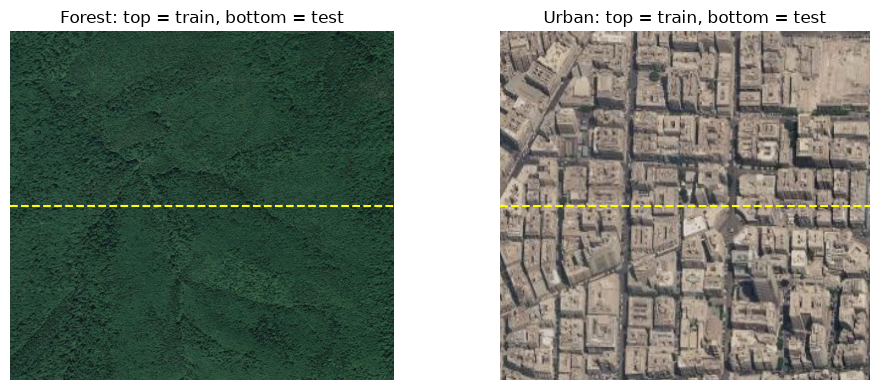

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Patch

rng = np.random.default_rng(42)
folder = Path('.')
if not (folder / 'forest.png').exists():
    folder = Path('ML4space/lab3')

forest = np.array(Image.open(folder / 'forest.png').convert('RGB'))
urban = np.array(Image.open(folder / 'urban.png').convert('RGB'))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, image, title in zip(axes, [forest, urban], ['Forest', 'Urban']):
    ax.imshow(image)
    ax.axhline(image.shape[0] // 2, color='yellow', linestyle='--')
    ax.set_title(title + ': top = train, bottom = test')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 1. Data

We take 400 random pixels from the top half of each training image.
Both classifiers use the same samples.

First, we check accuracy on the unused bottom halves, resized to 96 x 96 and joined together.
Then we classify the separate mixed image. Forest pixels are blue and urban pixels are red.

In [2]:
def training_pixels(image, n=400):
    pixels = image[:image.shape[0] // 2].reshape(-1, 3)
    indices = rng.choice(len(pixels), n, replace=False)
    return pixels[indices].astype(float)

forest_train = training_pixels(forest)
urban_train = training_pixels(urban)
X_train = np.vstack([forest_train, urban_train])
y_train = np.repeat([0, 1], [len(forest_train), len(urban_train)])

def test_part(image):
    bottom = image[image.shape[0] // 2:]
    return np.array(Image.fromarray(bottom).resize((96, 96), Image.Resampling.NEAREST))

test_image = np.concatenate([test_part(forest), test_part(urban)], axis=1)
X_test = test_image.reshape(-1, 3).astype(float)
y_true = np.concatenate([np.zeros((96, 96), dtype=int),
                         np.ones((96, 96), dtype=int)], axis=1).ravel()
palette = np.array([[0, 0, 255], [255, 0, 0]], dtype=np.uint8)

def show_results(predictions, titles):
    fig, axes = plt.subplots(1, len(predictions) + 1,
                             figsize=(5 * (len(predictions) + 1), 3))
    axes[0].imshow(test_image)
    axes[0].set_title('Test image: forest | urban')
    for ax, prediction, title in zip(axes[1:], predictions, titles):
        ax.imshow(palette[prediction.reshape(test_image.shape[:2])])
        ax.set_title(f'{title}\nAccuracy: {np.mean(prediction == y_true):.2%}')
    for ax in axes:
        ax.axis('off')
    fig.legend(handles=[Patch(color='blue', label='Forest'),
                        Patch(color='red', label='Urban')], loc='lower center', ncol=2)
    plt.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()

## 2. Bayes

We fit a normal distribution to each RGB channel in each class.
Its parameters are the sample mean and standard deviation, printed below.

$$p(x_j|c)=\frac{1}{\sigma_{cj}\sqrt{2\pi}}\exp\left(-\frac{(x_j-\mu_{cj})^2}{2\sigma_{cj}^2}\right)$$

We treat the channels as independent (naive Bayes). The histograms show the samples and the black lines show the fitted PDFs.

Forest
  R: mean = 36.00, std = 14.05
  G: mean = 65.39, std = 14.97
  B: mean = 50.71, std = 14.41
Urban
  R: mean = 140.34, std = 40.86
  G: mean = 130.24, std = 37.25
  B: mean = 121.55, std = 32.97


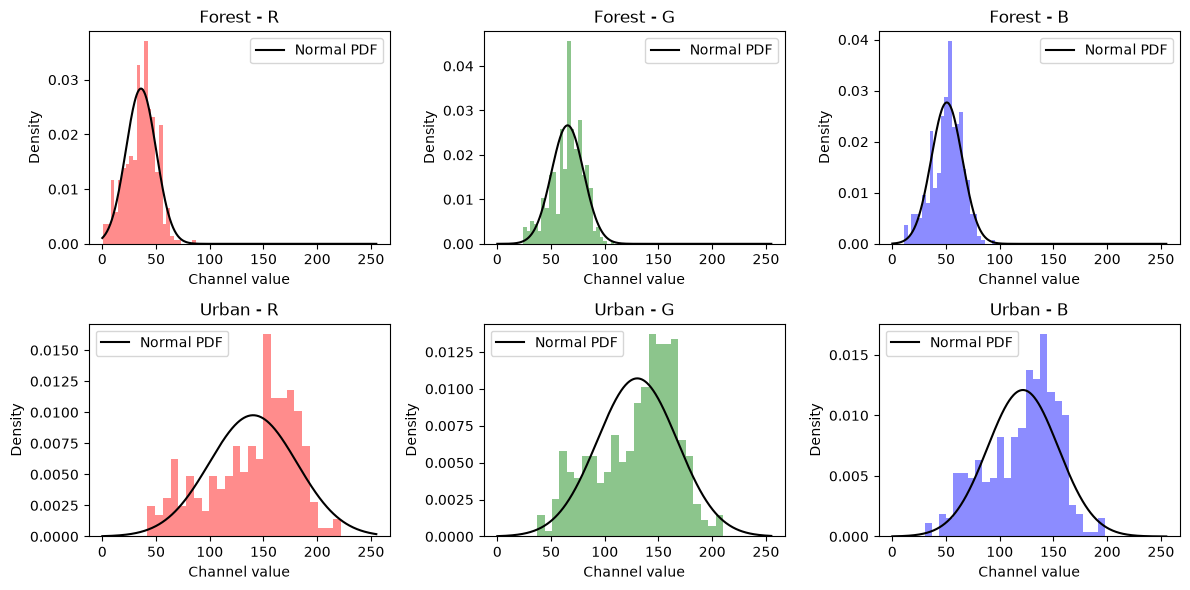

In [3]:
means = np.array([forest_train.mean(axis=0), urban_train.mean(axis=0)])
stds = np.array([forest_train.std(axis=0), urban_train.std(axis=0)])
stds = np.maximum(stds, 1e-6)
priors = np.array([0.5, 0.5])

for c, name in enumerate(['Forest', 'Urban']):
    print(name)
    for j, channel in enumerate('RGB'):
        print(f'  {channel}: mean = {means[c, j]:.2f}, std = {stds[c, j]:.2f}')

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
grid = np.linspace(0, 255, 512)
for c, samples in enumerate([forest_train, urban_train]):
    for j, color in enumerate(['red', 'green', 'blue']):
        ax = axes[c, j]
        ax.hist(samples[:, j], bins=25, density=True, color=color, alpha=0.45)
        mu, sigma = means[c, j], stds[c, j]
        pdf = np.exp(-0.5 * ((grid - mu) / sigma)**2) / (sigma * np.sqrt(2 * np.pi))
        ax.plot(grid, pdf, color='black', label='Normal PDF')
        ax.set_title(f'{["Forest", "Urban"][c]} - {"RGB"[j]}')
        ax.set_xlabel('Channel value')
        ax.set_ylabel('Density')
        ax.legend()
plt.tight_layout()
plt.show()

### Pixel classification

Both class priors are 0.5. For each pixel, we choose the class with the higher score:

$$\mathrm{score}(c)=\log P(c)+\sum_{j\in\{R,G,B\}}\log p(x_j|c)$$

Logs help avoid very small numbers. The result is blue for forest and red for urban.

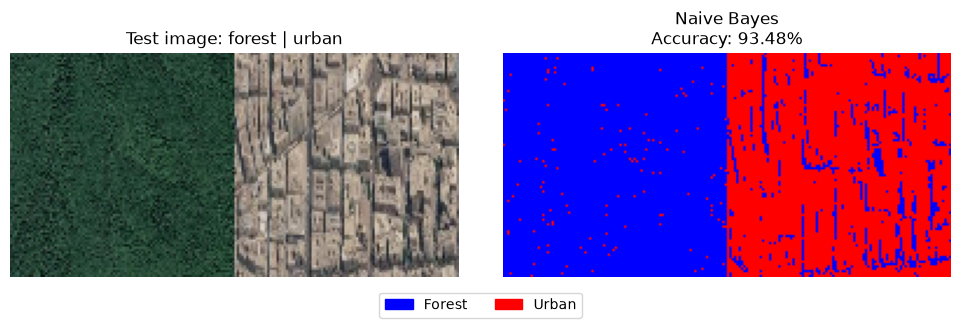

In [4]:
def bayes_predict(X):
    scores = []
    for c in [0, 1]:
        log_pdf = -np.log(stds[c] * np.sqrt(2 * np.pi)) - 0.5 * ((X - means[c]) / stds[c])**2
        scores.append(np.log(priors[c]) + log_pdf.sum(axis=1))
    return np.argmax(np.column_stack(scores), axis=1)

bayes_result = bayes_predict(X_test)
show_results([bayes_result], ['Naive Bayes'])

## 3. kNN

1. Calculate the distance from a test pixel to every training pixel.
2. Take the k closest samples.
3. Use their majority class.

We use squared RGB distance: $d^2=(R-R_i)^2+(G-G_i)^2+(B-B_i)^2$.
Taking the square root would give the same neighbours. We try k = 1, 3 and 5.
Pixels are processed in batches to save memory.

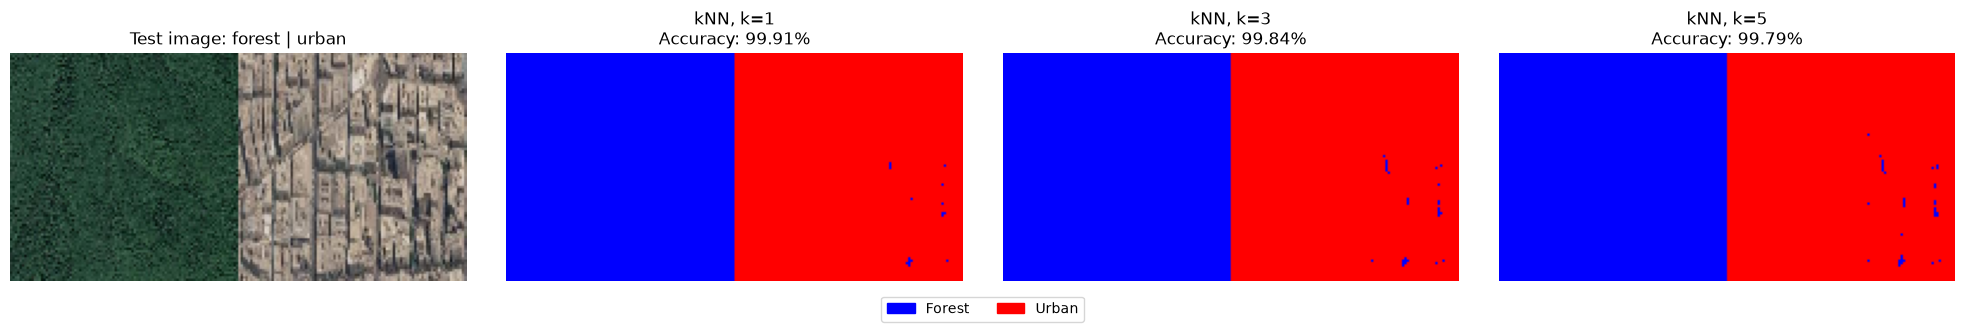

In [5]:
def knn_predict(X, ks=(1, 3, 5), batch_size=256):
    predictions = {k: np.empty(len(X), dtype=int) for k in ks}
    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size]
        distances = ((batch[:, None, :] - X_train[None, :, :])**2).sum(axis=2)
        nearest = np.argsort(distances, axis=1, kind='stable')[:, :max(ks)]
        labels = y_train[nearest]
        for k in ks:
            predictions[k][start:start + len(batch)] = (labels[:, :k].sum(axis=1) > k / 2).astype(int)
    return predictions

knn_results = knn_predict(X_test)
show_results([knn_results[k] for k in [1, 3, 5]], ['kNN, k=1', 'kNN, k=3', 'kNN, k=5'])

## 4. Check on the unused image halves

Here the labels are known: the left half is forest and the right half is urban.
Accuracy is the percentage of correct pixel labels. These are parts of the training images, so this is only a simple check.

In [6]:
results = {'Bayes': bayes_result, **{f'kNN k={k}': knn_results[k] for k in [1, 3, 5]}}
for name, prediction in results.items():
    forest_accuracy = np.mean(prediction[y_true == 0] == 0)
    urban_accuracy = np.mean(prediction[y_true == 1] == 1)
    print(f'{name:10s}: total {np.mean(prediction == y_true):.2%}, '
          f'forest {forest_accuracy:.2%}, urban {urban_accuracy:.2%}')

for a, b in [(1, 3), (3, 5)]:
    changed = np.count_nonzero(knn_results[a] != knn_results[b])
    print(f'k={a} to k={b}: {changed} pixels changed class')

Bayes     : total 93.48%, forest 98.56%, urban 88.40%
kNN k=1   : total 99.91%, forest 100.00%, urban 99.82%
kNN k=3   : total 99.84%, forest 100.00%, urban 99.67%
kNN k=5   : total 99.79%, forest 100.00%, urban 99.59%
k=1 to k=3: 15 pixels changed class
k=3 to k=5: 8 pixels changed class


## 5. New image

We load `urbanandforest.png` and resize it to at most 240 pixels per side to keep kNN fast.
Every pixel of the resized image is classified. The models stay the same.
The image also has a river. There is no water class, so it must get one of the two labels.

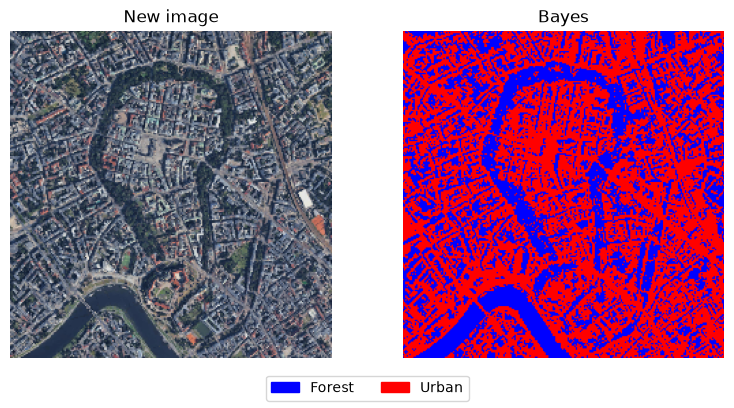

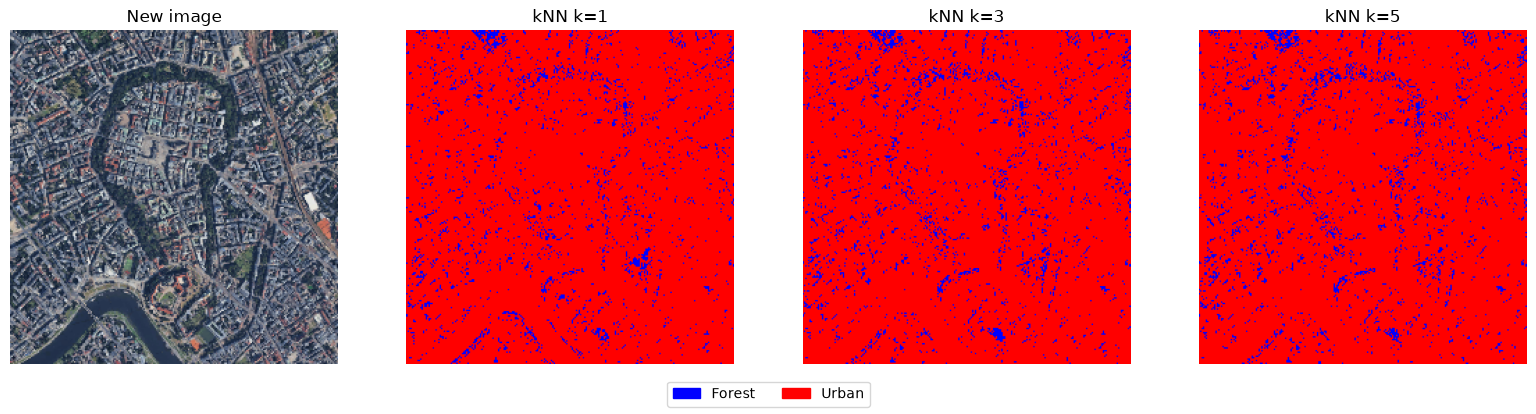

In [7]:
new_image = Image.open(folder / 'urbanandforest.png').convert('RGB')
new_image.thumbnail((240, 240), Image.Resampling.NEAREST)
new_image = np.array(new_image)
X_new = new_image.reshape(-1, 3).astype(float)

new_bayes = bayes_predict(X_new)
new_knn = knn_predict(X_new)

def show_new_results(predictions, titles):
    fig, axes = plt.subplots(1, len(predictions) + 1,
                             figsize=(4 * (len(predictions) + 1), 4))
    axes[0].imshow(new_image)
    axes[0].set_title('New image')
    for ax, prediction, title in zip(axes[1:], predictions, titles):
        ax.imshow(palette[prediction.reshape(new_image.shape[:2])])
        ax.set_title(title)
    for ax in axes:
        ax.axis('off')
    fig.legend(handles=[Patch(color='blue', label='Forest'),
                        Patch(color='red', label='Urban')], loc='lower center', ncol=2)
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

show_new_results([new_bayes], ['Bayes'])
show_new_results([new_knn[k] for k in [1, 3, 5]], ['kNN k=1', 'kNN k=3', 'kNN k=5'])

### Changing k

We count how many labels change on the new image. This measures the difference between the maps, not accuracy.
We do not have a labelled mask for this image, so we cannot calculate its accuracy.

In [8]:
for a, b in [(1, 3), (3, 5), (1, 5)]:
    changed = np.count_nonzero(new_knn[a] != new_knn[b])
    print(f'k={a} to k={b}: {changed} pixels changed ({changed / len(X_new):.2%})')

for name, prediction in [('Bayes', new_bayes)] + [(f'kNN k={k}', new_knn[k]) for k in [1, 3, 5]]:
    print(f'{name}: forest {np.mean(prediction == 0):.2%}, urban {np.mean(prediction == 1):.2%}')

k=1 to k=3: 1748 pixels changed (3.09%)
k=3 to k=5: 1078 pixels changed (1.90%)
k=1 to k=5: 1892 pixels changed (3.34%)
Bayes: forest 37.88%, urban 62.12%
kNN k=1: forest 5.82%, urban 94.18%
kNN k=3: forest 6.63%, urban 93.37%
kNN k=5: forest 6.68%, urban 93.32%


## Comments

On the unused halves, Bayes gives 93.48%. kNN gives 99.91% for k=1, 99.84% for k=3 and 99.79% for k=5.
The differences are small. k=1 works best on this check.

With k=1, one neighbour decides the class. With k=3 and k=5, more neighbours vote.
This can reduce the effect of unusual samples, but does not always improve the result.
The counts above show how much the new image changes.

Both methods only use colour. Dark roofs, shadows and water can look like forest pixels.
The new image also has different colours from the training images, so the result is less reliable.
Larger k does not use nearby image positions: it only uses nearby RGB colours.

On the new image, k=1 to k=3 changes 3.09% of labels. k=3 to k=5 changes 1.90%. The maps look similar.
Bayes marks the river and many shadows as forest. kNN labels most of the image as urban and misses much of the green belt. Neither method separates all areas correctly.
The forest-labelled share rises from 5.82% at k=1 to 6.68% at k=5. This is not an accuracy score.